# CS322 - Gold Trend Prediction with Least-Squares Regression

**Outcome variable (y):** gold closing price (USD/oz, COMEX gold futures), daily, last 2 years of data: 1 Feb 2024 – 30 Jan 2026 (set by `START_DATE` below)

**Predictor variables (x):** each one is analysed separately

| Analysis | x | Question |
|---|---|---|
| 1 | x₁ = time (years since the start date) | Does gold follow a trend over time? |
| 2 | x₂ = Bitcoin price on the same day (thousand USD) | Does "digital gold" move with real gold? |

**Notebook layout:** each function form has its own section.

- Section 3: Linear function, y = a + b·x
- Section 4: Polynomial of degree 2, y = a + b·x + c·x²
- Section 5: Exponential function, y = a·e^(b·x)
- Section 6: Comparison of all three
- Sections 7–8: Predictions and accuracy on unseen data

**Data files (same folder as this notebook):**
- `gold_historical_data.csv` (gold futures, Yahoo Finance)
- `bitcoin_historical_data.csv` (BTC/USD daily close, Bitstamp exchange)

Requirements: `pip install numpy pandas matplotlib`

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

START_DATE = '2024-02-01'   # analysis window: last 2 years of the gold data (change here to rescope)
TRAIN_END  = '2025-09-30'   # for the accuracy check: fit up to here, test on the remaining months

gold = pd.read_csv('gold_historical_data.csv', parse_dates=['Date'])[['Date', 'Close']]
btc = pd.read_csv('bitcoin_historical_data.csv', parse_dates=['date'])[['date', 'close']]
btc = btc.rename(columns={'date': 'Date', 'close': 'BTC'})

# Bitcoin trades 7 days a week, gold only on weekdays: keep the gold trading days
df = gold.merge(btc, on='Date', how='left').sort_values('Date')
df = df[df['Date'] >= START_DATE].reset_index(drop=True)
print(df.shape, df['Date'].min().date(), '->', df['Date'].max().date(),
      '| missing BTC values:', df['BTC'].isna().sum())
df.describe()

(503, 3) 2024-02-01 -> 2026-01-30 | missing BTC values: 0


,Date,Close,BTC
count,503,503.000000,503.000000
mean,2025-01-30 14:50:20.278330112,3027.915899,85864.652087
min,2024-02-01 00:00:00,1990.300049,42659.000000
25%,2024-08-01 12:00:00,2429.300049,66095.000000
50%,2025-01-31 00:00:00,2823.000000,88277.000000
75%,2025-07-31 12:00:00,3376.049927,103829.000000
max,2026-01-30 00:00:00,5318.399902,124728.000000
std,NaN,714.952137,20672.009194


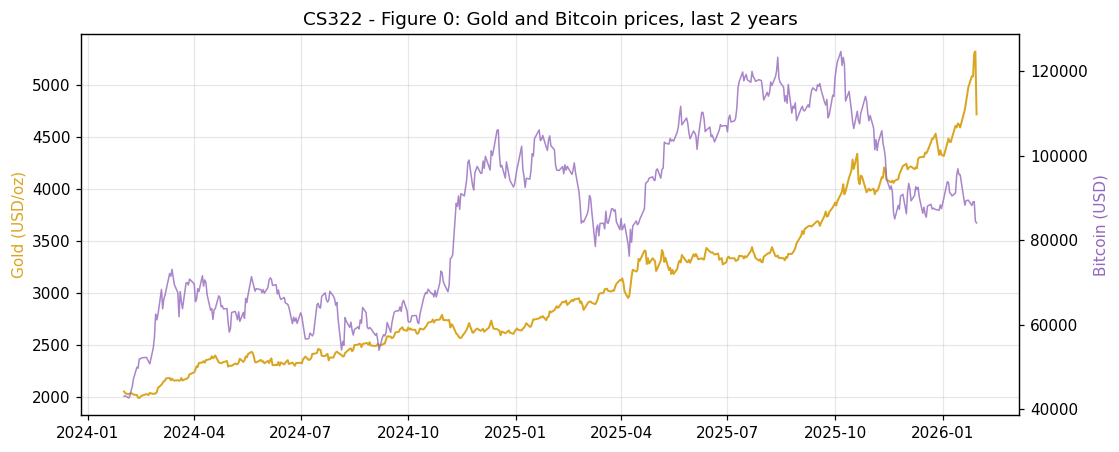

Correlation between gold and Bitcoin: 0.6551


In [ ]:
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(df['Date'], df['Close'], color='goldenrod', lw=1.3, label='Gold (USD/oz)')
ax1.set_ylabel('Gold (USD/oz)', color='goldenrod')
ax2 = ax1.twinx()
ax2.plot(df['Date'], df['BTC'], color='tab:purple', lw=1, alpha=0.8, label='Bitcoin (USD)')
ax2.set_ylabel('Bitcoin (USD)', color='tab:purple'); ax2.grid(False)
ax1.set_title('CS322 - Figure 0: Gold and Bitcoin prices, last 2 years')
fig.savefig('CS322_fig0_gold_bitcoin.png', bbox_inches='tight'); plt.show()
print('Correlation between gold and Bitcoin:', round(df['Close'].corr(df['BTC']), 4))

## 1. Least squares and the measures of fit

For a model y ≈ Aβ, least squares chooses β to minimise SSE = Σ(yᵢ − ŷᵢ)².
Setting the derivative to zero gives the **normal equations**:

$$A^T A\,\beta = A^T y$$

Each function form only changes the design matrix **A** (Sections 3–5).

**Measures of fit** (n = number of points, p = number of x terms):

| measure | formula |
|---|---|
| SSE | Σ(yᵢ − ŷᵢ)² |
| SST | Σ(yᵢ − ȳ)² |
| R² | 1 − SSE/SST |
| adjusted R² | 1 − (1 − R²)(n − 1)/(n − p − 1) |
| RMSE | √(SSE/n) |

**R² vs adjusted R²:** R² never decreases when a term (such as x²) is added. Adjusted R² subtracts a penalty for each extra term p, so it only rises if the new term really improves the fit.

In [ ]:
def solve_normal_equations(A, y):
    # Least-squares coefficients from (A^T A) beta = A^T y
    return np.linalg.solve(A.T @ A, A.T @ y)

def scores(y, y_hat, p):
    n = len(y)
    sse = np.sum((y - y_hat) ** 2)
    sst = np.sum((y - y.mean()) ** 2)
    r2 = 1 - sse / sst
    adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return dict(R2=r2, Adj_R2=adj, SSE=sse, RMSE=np.sqrt(sse / n))

def show_fit(form, color, models_for_form):
    # Plot one function form for both predictors, side by side
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    for ax, (name, d) in zip(axes, analyses.items()):
        f = models_for_form[name]
        ax.scatter(d['x'], y, s=4, color='grey', alpha=0.5, label='Data')
        xs = np.linspace(d['x'].min(), d['x'].max(), 400)
        r2 = scores(y, f(d['x']), P[form])['R2']
        ax.plot(xs, f(xs), color=color, lw=2.2, label=f'{form} fit (R² = {r2:.4f})')
        ax.set_xlabel(d['xlabel']); ax.set_ylabel('y = gold close (USD/oz)'); ax.legend()
        ax.set_title(name)
    fig.suptitle(f'CS322 - {form} function: least-squares fit of gold price')
    fig.tight_layout()
    return fig

FORMS = ['Linear', 'Quadratic', 'Exponential']
COLORS = {'Linear': 'tab:blue', 'Quadratic': 'tab:green', 'Exponential': 'tab:red'}
P = {'Linear': 1, 'Quadratic': 2, 'Exponential': 1}     # number of x terms in each form
FIT = {}          # the fitting function of each form (filled in Sections 3-5)
models = {}       # fitted model for each (predictor, form)
rows = []         # results table

## 2. Variables

- **y = gold close** in USD/oz
- **x₁ = time in years** since the first data point (0 = 1 Feb 2024, ≈ 2.0 = 30 Jan 2026)
- **x₂ = Bitcoin close in thousands of USD** on the same day (e.g. 84.13 = \$84,130). Scaling to thousands keeps x² small and the normal equations numerically stable; the fit itself is unchanged.

In [ ]:
y = df['Close'].to_numpy(float)
T0 = df['Date'].iloc[0]
x_time = ((df['Date'] - T0).dt.days / 365.25).to_numpy()
x_btc = df['BTC'].to_numpy(float) / 1000

analyses = {
    'x1: time': dict(x=x_time, xlabel='x₁ = years since ' + START_DATE),
    'x2: Bitcoin': dict(x=x_btc, xlabel='x₂ = Bitcoin price (thousand USD)'),
}
print('n =', len(y))

n = 503


## 3. Linear function: y = a + b·x

A straight line: gold changes by the same amount **b** for each unit of x.

Design matrix and unknowns:

$$A = \begin{bmatrix} 1 & x_1 \\ 1 & x_2 \\ \vdots & \vdots \\ 1 & x_n \end{bmatrix}, \qquad \beta = \begin{bmatrix} a \\ b \end{bmatrix}$$

Solve (AᵀA)β = Aᵀy. For the linear case this is the same as
b = Σ(xᵢ − x̄)(yᵢ − ȳ) / Σ(xᵢ − x̄)²  and  a = ȳ − b·x̄.

In [ ]:
def fit_linear(x, y):
    A = np.column_stack([np.ones_like(x), x])       # columns [1, x]
    a, b = solve_normal_equations(A, y)
    return (a, b), (lambda t: a + b * t)

FIT['Linear'] = fit_linear
lin = {}
for name, d in analyses.items():
    (a, b), f = fit_linear(d['x'], y)
    lin[name] = models[(name, 'Linear')] = f
    s = scores(y, f(d['x']), P['Linear'])
    rows.append({'Predictor': name, 'Form': 'Linear', 'Equation': f'y = {a:.4g} + {b:.4g}x', **s})
    print(f'{name:12s}  y = {a:.4f} + {b:.4f}x   R² = {s["R2"]:.4f}  adj R² = {s["Adj_R2"]:.4f}  RMSE = {s["RMSE"]:.2f}')

x1: time      y = 1846.8643 + 1183.0978x   R² = 0.9123  adj R² = 0.9121  RMSE = 211.56
x2: Bitcoin   y = 1082.3730 + 22.6583x   R² = 0.4292  adj R² = 0.4281  RMSE = 539.62


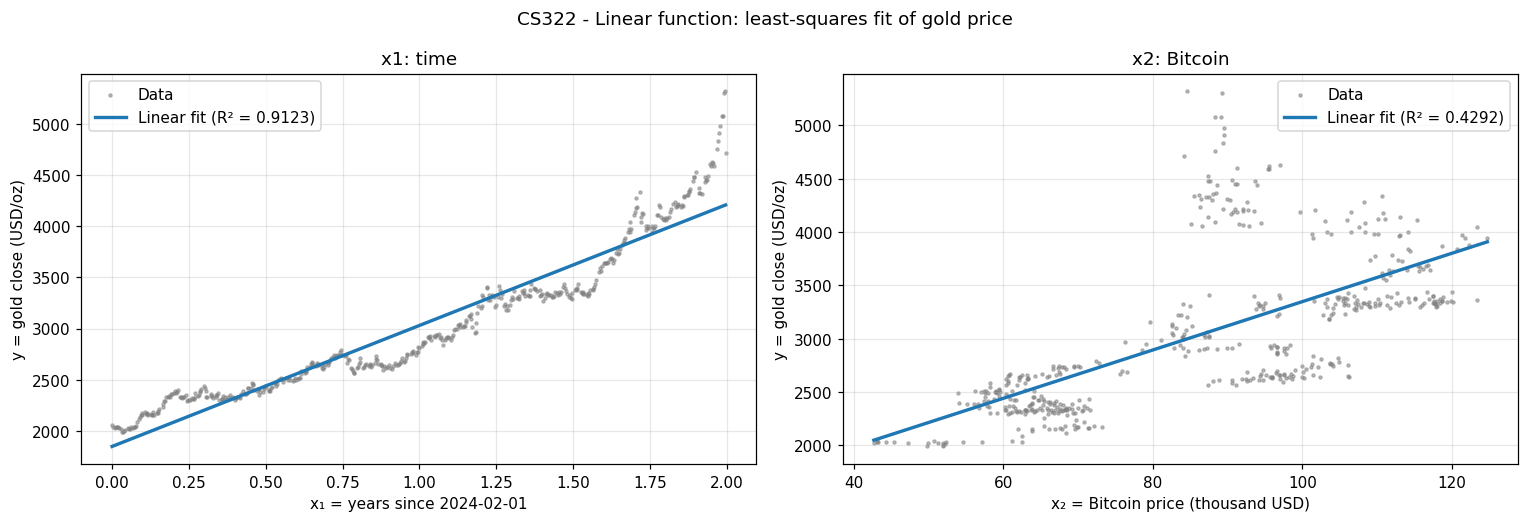

In [ ]:
fig = show_fit('Linear', COLORS['Linear'], lin)
fig.savefig('CS322_fig1_linear.png', bbox_inches='tight'); plt.show()

## 4. Polynomial of degree 2 (quadratic): y = a + b·x + c·x²

A curve that can bend: the x² term lets the rate of change speed up (c > 0) or slow down (c < 0).

Design matrix and unknowns (one extra column for x²):

$$A = \begin{bmatrix} 1 & x_1 & x_1^2 \\ 1 & x_2 & x_2^2 \\ \vdots & \vdots & \vdots \\ 1 & x_n & x_n^2 \end{bmatrix}, \qquad \beta = \begin{bmatrix} a \\ b \\ c \end{bmatrix}$$

Solve the 3×3 system (AᵀA)β = Aᵀy.

In [ ]:
def fit_quadratic(x, y):
    A = np.column_stack([np.ones_like(x), x, x**2])  # columns [1, x, x^2]
    a, b, c = solve_normal_equations(A, y)
    return (a, b, c), (lambda t: a + b * t + c * t**2)

FIT['Quadratic'] = fit_quadratic
quad = {}
for name, d in analyses.items():
    (a, b, c), f = fit_quadratic(d['x'], y)
    quad[name] = models[(name, 'Quadratic')] = f
    s = scores(y, f(d['x']), P['Quadratic'])
    rows.append({'Predictor': name, 'Form': 'Quadratic', 'Equation': f'y = {a:.4g} + {b:.4g}x + {c:.4g}x²', **s})
    print(f'{name:12s}  y = {a:.4f} + {b:.4f}x + {c:.4f}x²   R² = {s["R2"]:.4f}  adj R² = {s["Adj_R2"]:.4f}  RMSE = {s["RMSE"]:.2f}')

x1: time      y = 2217.6379 + 66.2790x + 559.8932x²   R² = 0.9664  adj R² = 0.9663  RMSE = 130.94
x2: Bitcoin   y = -1296.8964 + 81.8575x + -0.3467x²   R² = 0.4613  adj R² = 0.4591  RMSE = 524.23


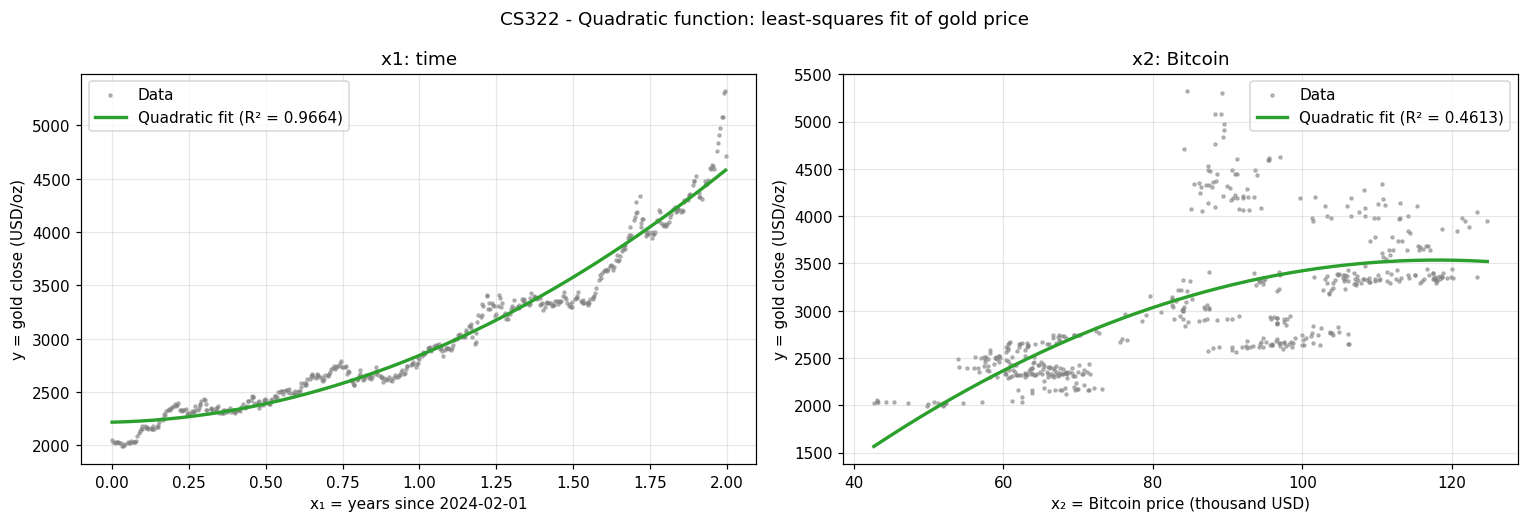

In [ ]:
fig = show_fit('Quadratic', COLORS['Quadratic'], quad)
fig.savefig('CS322_fig2_quadratic.png', bbox_inches='tight'); plt.show()

## 5. Exponential function: y = a·e^(b·x)

Grows by the same **percentage** for each unit of x, like compound interest (growth of (e^b − 1) × 100% per unit).

This is not linear in a and b, so take ln of both sides:

$$\ln y = \ln a + b\,x$$

which is a straight line in x. Fit it with

$$A = \begin{bmatrix} 1 & x_1 \\ \vdots & \vdots \\ 1 & x_n \end{bmatrix}, \qquad \beta = \begin{bmatrix} \ln a \\ b \end{bmatrix}, \qquad \text{target } \ln y$$

then convert back: a = e^β₀, b = β₁. R² is computed on the original y (dollars), so it compares fairly with Sections 3–4.

In [ ]:
def fit_exponential(x, y):
    A = np.column_stack([np.ones_like(x), x])        # columns [1, x]
    ln_a, b = solve_normal_equations(A, np.log(y))   # fit ln(y) = ln(a) + b x
    a = np.exp(ln_a)
    return (a, b), (lambda t: a * np.exp(b * t))

FIT['Exponential'] = fit_exponential
expo = {}
for name, d in analyses.items():
    (a, b), f = fit_exponential(d['x'], y)
    expo[name] = models[(name, 'Exponential')] = f
    s = scores(y, f(d['x']), P['Exponential'])
    rows.append({'Predictor': name, 'Form': 'Exponential', 'Equation': f'y = {a:.4g}·e^({b:.4g}x)', **s})
    print(f'{name:12s}  y = {a:.4f}·e^({b:.6f}x)   growth {(np.exp(b)-1)*100:.2f}% per unit   '
          f'R² = {s["R2"]:.4f}  adj R² = {s["Adj_R2"]:.4f}  RMSE = {s["RMSE"]:.2f}')

x1: time      y = 2011.8835·e^(0.383296x)   growth 46.71% per unit   R² = 0.9466  adj R² = 0.9465  RMSE = 165.03
x2: Bitcoin   y = 1513.3921·e^(0.007772x)   growth 0.78% per unit   R² = 0.4070  adj R² = 0.4058  RMSE = 550.03


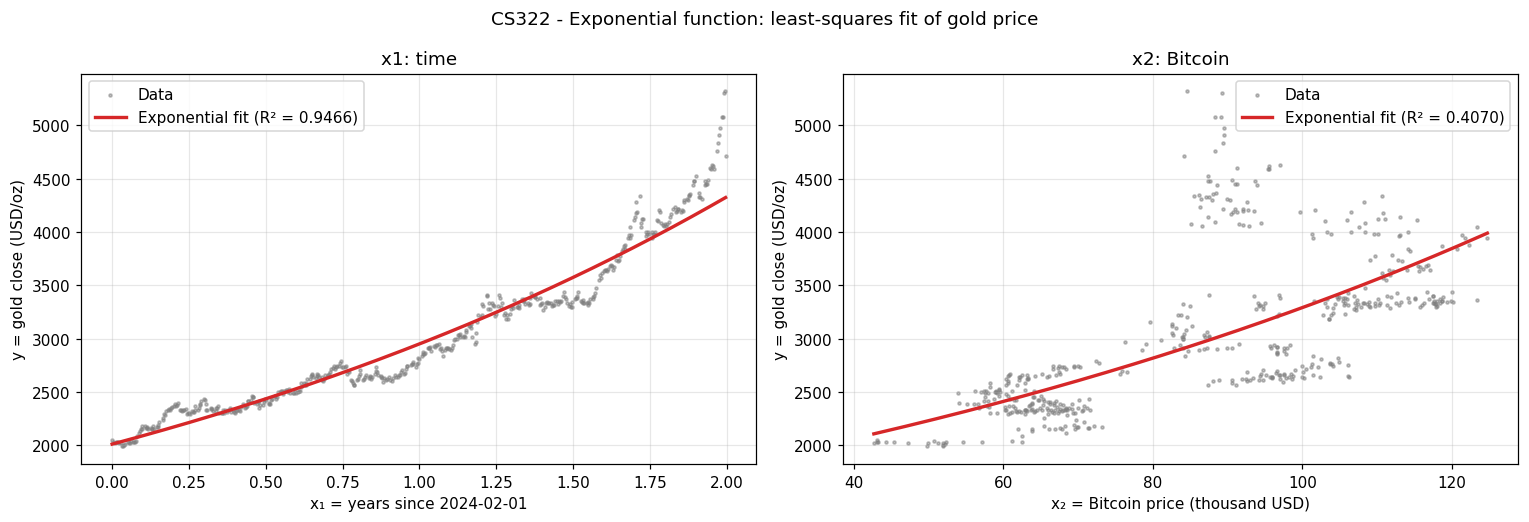

In [ ]:
fig = show_fit('Exponential', COLORS['Exponential'], expo)
fig.savefig('CS322_fig3_exponential.png', bbox_inches='tight'); plt.show()

## 6. Comparison of the three function forms

In [ ]:
results = pd.DataFrame(rows)
results['Form'] = pd.Categorical(results['Form'], FORMS, ordered=True)   # keep Linear, Quadratic, Exponential order
results = results.sort_values(['Predictor', 'Form']).reset_index(drop=True)
results.to_csv('regression_results.csv', index=False)
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 160)
print('CS322 - Table 1: Least-squares fits of gold price (n = %d)' % len(y))
results.round({'R2': 4, 'Adj_R2': 4, 'SSE': 0, 'RMSE': 2})

CS322 - Table 1: Least-squares fits of gold price (n = 503)


,Predictor,Form,Equation,R2,Adj_R2,SSE,RMSE
0,x1: time,Linear,y = 1847 + 1183x,0.9123,0.9121,22512201.0,211.56
1,x1: time,Quadratic,y = 2218 + 66.28x + 559.9x²,0.9664,0.9663,8624169.0,130.94
2,x1: time,Exponential,y = 2012·e^(0.3833x),0.9466,0.9465,13698733.0,165.03
3,x2: Bitcoin,Linear,y = 1082 + 22.66x,0.4292,0.4281,146466469.0,539.62
4,x2: Bitcoin,Quadratic,y = -1297 + 81.86x + -0.3467x²,0.4613,0.4591,138233878.0,524.23
5,x2: Bitcoin,Exponential,y = 1513·e^(0.007772x),0.4070,0.4058,152174120.0,550.03


In [ ]:
for name in analyses:
    best = results[results['Predictor'] == name].sort_values('Adj_R2', ascending=False).iloc[0]
    print(f'Best form for {name}: {best["Form"]}  (adj R² = {best["Adj_R2"]:.4f}, RMSE = {best["RMSE"]:.2f})')

Best form for x1: time: Quadratic  (adj R² = 0.9663, RMSE = 130.94)
Best form for x2: Bitcoin: Quadratic  (adj R² = 0.4591, RMSE = 524.23)


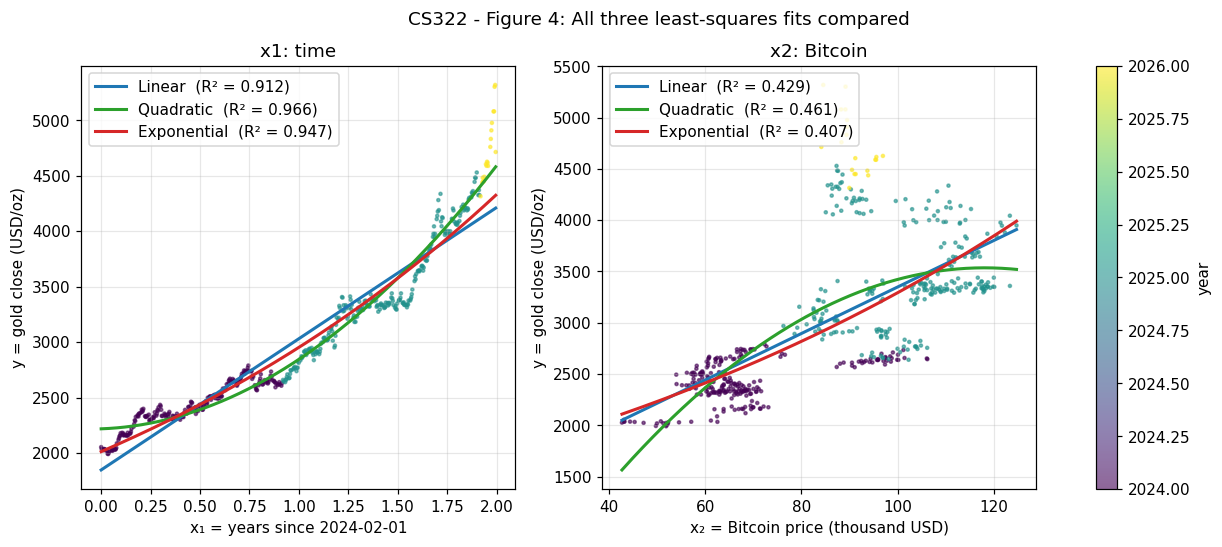

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, d) in zip(axes, analyses.items()):
    sc = ax.scatter(d['x'], y, s=4, c=df['Date'].dt.year, cmap='viridis', alpha=0.6)
    xs = np.linspace(d['x'].min(), d['x'].max(), 400)
    for form in FORMS:
        r2 = results.query('Predictor == @name and Form == @form')['R2'].item()
        ax.plot(xs, models[(name, form)](xs), color=COLORS[form], lw=2, label=f'{form}  (R² = {r2:.3f})')
    ax.set_xlabel(d['xlabel']); ax.set_ylabel('y = gold close (USD/oz)')
    ax.set_title(name); ax.legend(loc='upper left')
plt.colorbar(sc, ax=axes, label='year')
fig.suptitle('CS322 - Figure 4: All three least-squares fits compared')
fig.savefig('CS322_fig4_comparison.png', bbox_inches='tight'); plt.show()

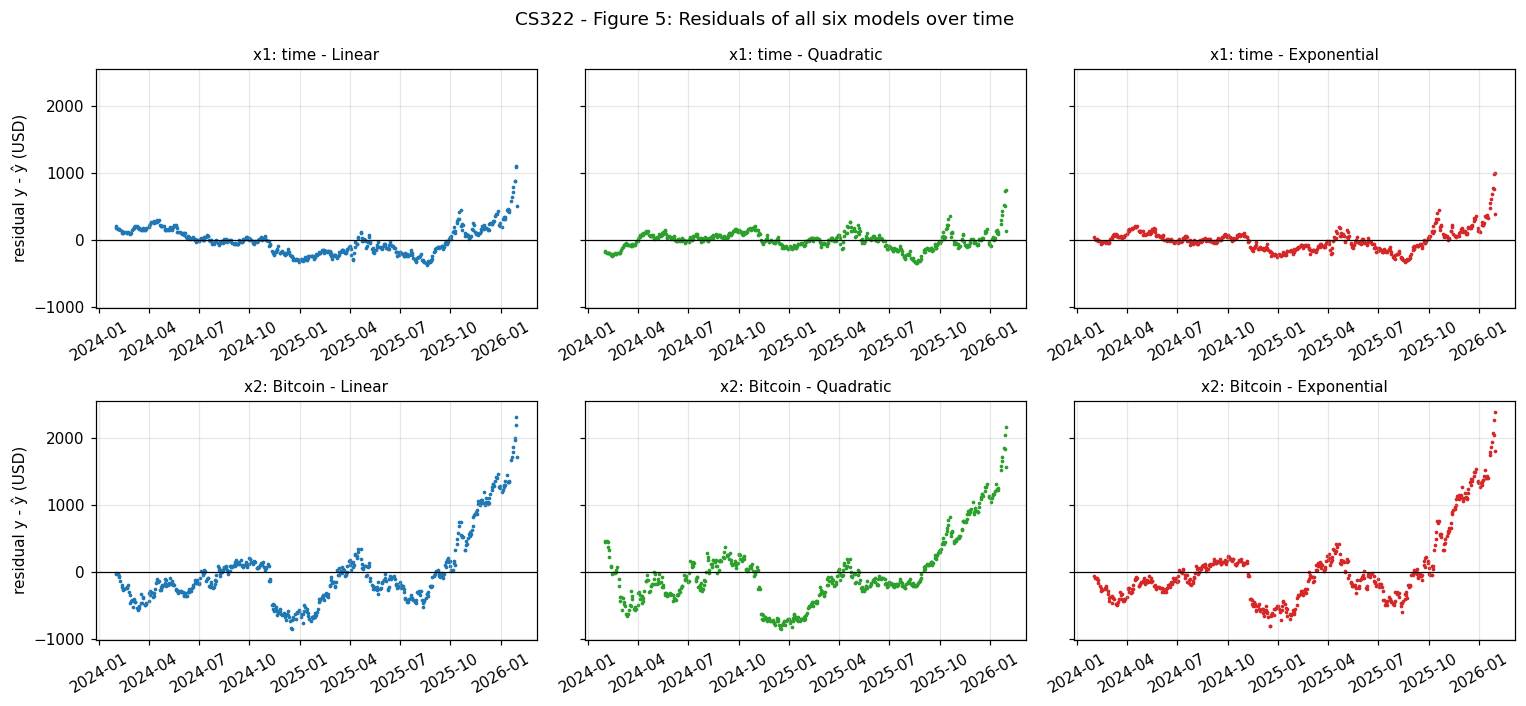

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharey=True)
for row, name in zip(axes, analyses):
    for ax, form in zip(row, FORMS):
        ax.scatter(df['Date'], y - models[(name, form)](analyses[name]['x']), s=2, color=COLORS[form])
        ax.axhline(0, color='black', lw=0.8); ax.set_title(f'{name} - {form}', fontsize=10)
        ax.tick_params(axis='x', labelrotation=30)
    row[0].set_ylabel('residual y - ŷ (USD)')
fig.suptitle('CS322 - Figure 5: Residuals of all six models over time')
fig.tight_layout(); fig.savefig('CS322_fig5_residuals.png', bbox_inches='tight'); plt.show()

## 7. Using the models for prediction

**Time models (x₁):** predict the gold price on a future date.
**Bitcoin models (x₂):** predict the gold price from the Bitcoin price on the same day.

Both are checked against the real gold price on **9 Nov 2026 ≈ \$4,123/oz** (Fortune, 9 Nov 2026). Bitcoin closed at **\$75,266.85** that day (Bitstamp).

In [ ]:
ACTUAL_GOLD = 4123.0
btc_full = pd.read_csv('bitcoin_historical_data.csv', parse_dates=['date']).set_index('date')['close']

pred_rows = []
for date in ['2026-02-02', '2026-06-30', '2026-11-09']:
    xt = (pd.Timestamp(date) - T0).days / 365.25
    xb = btc_full.get(pd.Timestamp(date), np.nan) / 1000
    for name, xv in [('x1: time', xt), ('x2: Bitcoin', xb)]:
        row = {'Date': date, 'Predictor': name, 'x': round(xv, 3)}
        for form in FORMS:
            row[form] = models[(name, form)](xv)
        row['Actual gold'] = ACTUAL_GOLD if date == '2026-11-09' else np.nan
        pred_rows.append(row)
pred = pd.DataFrame(pred_rows)
print('CS322 - Table 2: Example predictions of gold price (USD/oz)')
pred.round(1)

CS322 - Table 2: Example predictions of gold price (USD/oz)


,Date,Predictor,x,Linear,Quadratic,Exponential,Actual gold
0,2026-02-02,x1: time,2.0,4217.9,4599.2,4337.2,NaN
1,2026-02-02,x2: Bitcoin,78.7,2864.8,2997.1,2789.2,NaN
2,2026-06-30,x1: time,2.4,4697.3,5627.4,5066.0,NaN
3,2026-06-30,x2: Bitcoin,58.5,2408.5,2306.4,2385.1,NaN
4,2026-11-09,x1: time,2.8,5124.9,6699.5,5818.7,4123.0
5,2026-11-09,x2: Bitcoin,75.3,2787.8,2900.3,2716.5,4123.0


## 8. Accuracy check on unseen data: fit on Feb 2024 – Sep 2025, test on Oct 2025 – Jan 2026

R² on the data used for fitting only measures **fit**. To measure **prediction**, each model is refitted using only data up to `TRAIN_END` (30 Sep 2025), then used to predict Oct 2025 – Jan 2026, which it never saw.

In [ ]:
train = (df['Date'] <= TRAIN_END).to_numpy()
test_rows, test_preds = [], {}
for name, d in analyses.items():
    for form in FORMS:
        _, f = FIT[form](d['x'][train], y[train])
        test_preds[(name, form)] = f(d['x'])
        s = scores(y[~train], f(d['x'][~train]), P[form])
        test_rows.append({'Predictor': name, 'Form': form,
                          'Train R2': scores(y[train], f(d['x'][train]), P[form])['R2'],
                          'Test R2': s['R2'], 'Test RMSE': s['RMSE']})
test = pd.DataFrame(test_rows)
print('CS322 - Table 3: Fit up to ' + TRAIN_END + ', tested on the rest')
test.round(3)

CS322 - Table 3: Fit up to 2025-09-30, tested on the rest


,Predictor,Form,Train R2,Test R2,Test RMSE
0,x1: time,Linear,0.951,-2.976,631.542
1,x1: time,Quadratic,0.962,-1.023,450.533
2,x1: time,Exponential,0.961,-1.577,508.475
3,x2: Bitcoin,Linear,0.736,-16.604,1328.964
4,x2: Bitcoin,Quadratic,0.739,-17.092,1347.263
5,x2: Bitcoin,Exponential,0.739,-17.315,1355.546


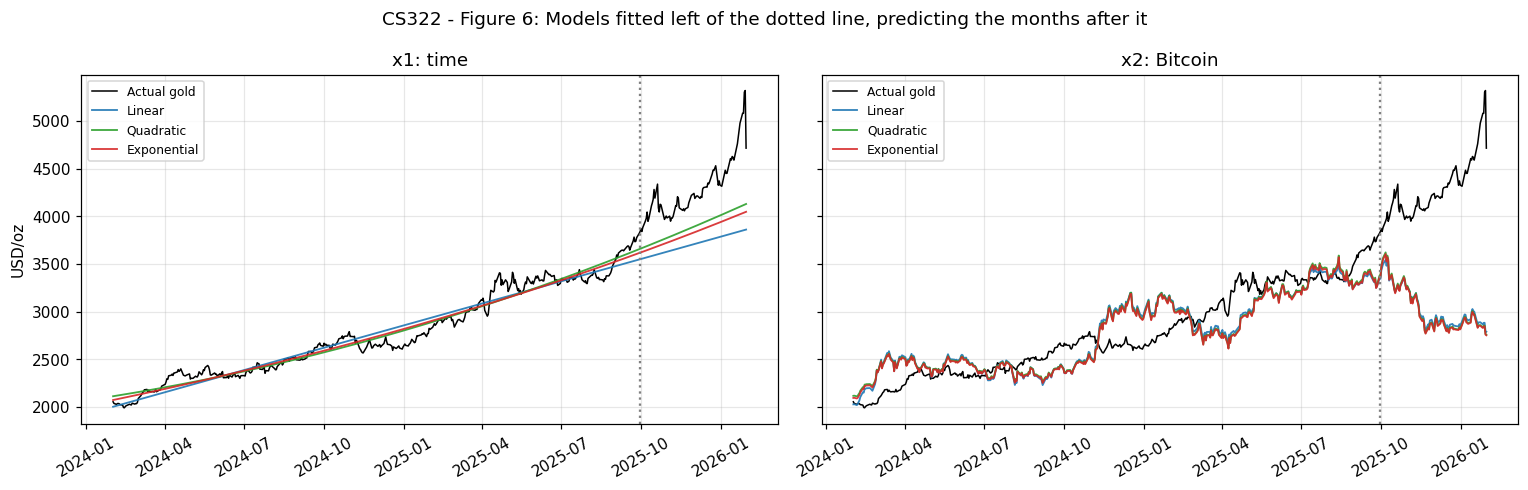

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, name in zip(axes, analyses):
    ax.plot(df['Date'], y, color='black', lw=1, label='Actual gold')
    for form in FORMS:
        ax.plot(df['Date'], test_preds[(name, form)], color=COLORS[form], lw=1.2, alpha=0.9, label=form)
    ax.axvline(pd.Timestamp(TRAIN_END), color='grey', ls=':')
    ax.set_title(name); ax.legend(loc='upper left', fontsize=8)
    ax.tick_params(axis='x', labelrotation=30)
axes[0].set_ylabel('USD/oz')
fig.suptitle('CS322 - Figure 6: Models fitted left of the dotted line, predicting the months after it')
fig.tight_layout(); fig.savefig('CS322_fig6_test.png', bbox_inches='tight'); plt.show()